In [1]:
import pennylane as qml
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
###
import numpy as np


# Added to silence some warnings.
jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).
# jax.config.update("jax_platform_name", "cpu") # Force cpu.
# jax.config.update('jax_dynamic_shapes', True)


jax.print_environment_info()

jax:    0.4.28
jaxlib: 0.4.28
numpy:  2.3.1
python: 3.12.10 (main, May 12 2025, 15:49:11) [Clang 17.0.0 (clang-1700.0.13.3)]
jax.devices (1 total, 1 local): [CpuDevice(id=0)]
process_count: 1
platform: uname_result(system='Darwin', node='papaya.local', release='24.5.0', version='Darwin Kernel Version 24.5.0: Tue Apr 22 19:53:27 PDT 2025; root:xnu-11417.121.6~2/RELEASE_ARM64_T6041', machine='arm64')



In [2]:
key = jax.random.PRNGKey(42)

In [3]:
# dev = qml.device("default.qubit")
# dev = qml.device("default.qubit", shots=100) # No seed, measurement results will be the same between runs.
dev = qml.device("default.qubit", shots=100, seed=key) # No seed, measurement results will be the same between runs.

In [4]:
def is_unitary(m: jnp.ndarray):
    return jnp.allclose(jnp.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: jnp.ndarray):
    return jnp.allclose(m, m.T.conj())

def is_sorted(x: jnp.ndarray):
    x = jnp.array(x)
    return bool(jnp.all(x[:-1] <= x[1:]))

def softmax(x: jnp.ndarray, axis=None):
    y = jnp.exp(x - jnp.max(x, axis=axis, keepdims=True)) # Stabilize to prevent overflow.
    return y / jnp.sum(y, axis=axis, keepdims=True)

In [5]:
from typing import Any, Callable

@qml.qnode(dev, interface='jax')
# @qml.qnode(dev)
# def circuit(
def dynamic_circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [6]:
def prepare_actions(
    wires_actions: list[int],
    action_probs_vec: jnp.ndarray, # shape (n_actions,),
    normalize: bool = False,
    ):
    # n_actions = action_probs_vec.shape[0]
    
    # d_actions = int(jnp.round(jnp.log2(n_actions)).item())
    # # print(f"{jnp.log2(n_actions)=}")
    # # print(f"{jnp.log2(n_actions).astype(jnp.int64)=}")
    # # print(f"{int(jnp.round(jnp.log2(n_actions)).item())=}")
    # # print(f"{jnp.log2(n_actions).item()=}")
    # # print(f"{d_actions=}")
    # if n_actions != 2**d_actions:
    #     raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(jnp.sqrt(action_probs_vec), wires=wires_actions, normalize=normalize) # Must normalize since inputs are probability vectors.


def prepare_returns(
    wires_actions: list[int],
    wires_returns: list[int],
    returns_probs_matrix: jnp.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    n_actions, n_returns = returns_probs_matrix.shape
    
    # d_returns = int(jnp.round(jnp.log2(n_returns)).item())
    # # print(f"{d_returns=}")
    # if n_returns != 2**d_returns:
    #     raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(jnp.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)


# def prepare_action_returns(
#     wires: list[int], 
#     action_probs_vec: jnp.ndarray, # shape (n_actions,),
#     returns_probs_matrix: jnp.ndarray, # shape (n_actions, n_returns)
#     normalize: bool = False,
#     ):
#     # print(f"{action_probs_vec.shape=}")
#     # print(f"{returns_probs_matrix.shape=}")
#     n_actions = action_probs_vec.shape[0]
#     n_returns = returns_probs_matrix.shape[1]
    
#     # Get number of qubits needed for actions and returns.
#     # (for now) The number of actions and returns must be powers of 2 for this to work properly.
#     d_actions = int(jnp.round(jnp.log2(n_actions)).item())
#     # print(f"{d_actions=}")
#     if n_actions != 2**d_actions:
#         raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
#     d_returns = int(jnp.round(jnp.log2(n_returns)).item())
#     # print(f"{d_returns=}")
#     if n_returns != 2**d_returns:
#         raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
#     # Partition wires into action and return wires.
#     # Wire order is: [action wires, return wires]
#     if len(wires) != d_actions + d_returns:
#         raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
#     wires_action = wires[:d_actions]
#     wires_returns = wires[d_actions:]
#     # print(f"{wires_action=}, {wires_returns=}")
    
#     # Create quantum state based on probability distribution for actions.
#     qml.StatePrep(jnp.sqrt(action_probs_vec), wires=wires_action, normalize=normalize) # Must normalize since inputs are probability vectors.
    
#     # Create operations that prepare return distributions for each action.
#     # Every action index must be represented. If no returns are generated
#     # for an action, then the operation should be the Identity.
#     ops = [
#         qml.StatePrep(jnp.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
#         for i in range(n_actions)
#     ]
#     qml.Select(ops, control=wires_action)

In [7]:
def circuit(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms):
    """Distributional returns comparison circuit.
    Two sets of qubits: actions, and return-atoms. Kicks back expectation of return-atoms to action distribution, which in turn weights the action distribution by the relative expected return.
    """
    wires = list(range(d_actions + d_returns))
    wires_actions = wires[:d_actions]
    wires_returns = wires[d_actions:]
    
    # Prepare initial action distribution, and return-atom distribution for each action.
    prepare_actions(wires_actions=wires_actions, action_probs_vec=action_probs_vec, normalize=True)
    prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True)
    
    # Apply the (non-unitary) return-atom-value operation.
    qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    
    # Measure the return-atom qubits to collapse their state, then reset to zero.
    for w in wires_returns:
        qml.measure(wires=w, reset=True)
    
    # Re-upload initial return-atom distribution for every action, apply the return-atom-value operation, and then measure/reset to collapse the return-atom qubits.
    n_returns = int(2**d_returns)
    n_actions = int(2**d_actions)
    # n_reuploads = n_returns
    # n_reuploads = n_returns*2
    # n_reuploads = n_actions
    n_reuploads = d_returns
    for _ in range(n_reuploads):
        prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True)
        qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
        for w in wires_returns:
            qml.measure(wires=w, reset=True)
    
    return qml.probs(wires=wires_actions), qml.probs(wires=wires_returns)

In [8]:
from functools import partial
@partial(jax.jit, static_argnames=['d_actions', 'd_returns', 'shots'])
def circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, shots=None):
    
    # Device construction inside `jax.jit`.
    dev = qml.device("default.qubit", shots=shots, seed=key)
    qnode = qml.QNode(circuit, device=dev, interface="jax", diff_method=None)
    return qnode(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms)

In [9]:
# n_actions = 16 # 4, 8, 16, 32, 64
# n_returns = 4 # 4, 8, 16, 32, 64
# d_actions = int(jnp.round(jnp.log2(n_actions)).item())
# d_returns = int(jnp.round(jnp.log2(n_returns)).item())
d_actions = 2
d_returns = 3
n_actions = 2**d_actions
n_returns = 2**d_returns

print(f"{n_actions=}")
print(f"{n_returns=}")
print(f"{d_actions=}")
print(f"{d_returns=}")

n_actions=4
n_returns=8
d_actions=2
d_returns=3


In [10]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([2465931498, 3679230171], dtype=uint32)


In [11]:
returns_probs_matrix = jnp.abs(jax.random.normal(key, shape=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / jnp.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

In [12]:
returns_probs_matrix

Array([[0.16177153, 0.04326164, 0.16010475, 0.05509025, 0.12617023,
        0.18437717, 0.09229685, 0.17692758],
       [0.15308155, 0.21324143, 0.23674317, 0.14693031, 0.09005353,
        0.0312384 , 0.11938606, 0.00932555],
       [0.16185213, 0.28147968, 0.00981777, 0.17670383, 0.21849669,
        0.08751234, 0.01515323, 0.04898433],
       [0.17748319, 0.08551325, 0.19144616, 0.13634503, 0.05227222,
        0.11650582, 0.17271422, 0.06772011]], dtype=float64)

In [13]:
returns_probs_matrix.sum(axis=1)

Array([1., 1., 1., 1.], dtype=float64)

In [14]:
# returns_atoms_values_original = jnp.array([-1,0,1,100])
# returns_atoms_values_original = jnp.array([-10,0,1,100])
# returns_atoms_values_original = jnp.array([-100,-10,0,1])
# returns_atoms_values_original = jnp.array([-1,0,1,10])
# returns_atoms_values_original = jnp.array([-1,0,1,2])
returns_atoms_values_original = jnp.array([float(i)+1 for i in range(n_returns)])/n_returns*4 # Steep exponential.
# returns_atoms_values_original = np.array([float(i)+1 for i in range(n_returns)])/n_returns*10 # Steep exponential.
returns_atoms_values_original_normalized = softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = jax.nn.softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2) / (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2).sum() # Turn into probability distribution with some adjustment to ensure that the minimum is close to zero but not exactly zero.

# returns_atoms_values = returns_atoms_values_original_normalized.copy()
returns_atoms_values = returns_atoms_values_original_normalized.copy()
returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) # values - epsilon (epsilon is zero).
# returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) - 3.6e-2 # values - epsilon.
# returns_atoms_values = returns_atoms_values/returns_atoms_values.max()

U_returns_atoms = jnp.diag(returns_atoms_values)

In [15]:
returns_atoms_values_original_normalized.sum()

Array(1., dtype=float64)

In [16]:
returns_atoms_values_original

Array([0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. ], dtype=float64)

In [17]:
returns_atoms_values

Array([0.31117103, 0.39955152, 0.5130343 , 0.65874908, 0.84585057,
       1.08609363, 1.39457182, 1.79066566], dtype=float64)

In [18]:
U_returns_atoms

Array([[0.31117103, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.39955152, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.5130343 , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.65874908, 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.84585057,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        1.08609363, 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 1.39457182, 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 1.79066566]], dtype=float64)

In [19]:
action_probs_vec_original = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec_original = jnp.array(action_probs_vec_original) # Convert to jax array for vectorization.
action_probs_vec = action_probs_vec_original.copy() # Preserve the original.

In [20]:
action_probs_vec

Array([0.25, 0.25, 0.25, 0.25], dtype=float64)

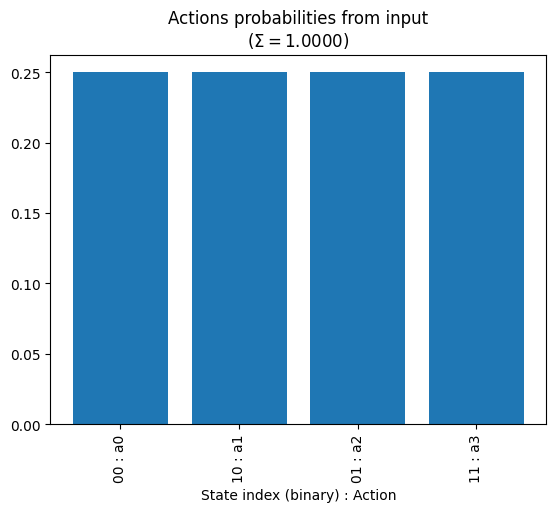

<Figure size 640x480 with 0 Axes>

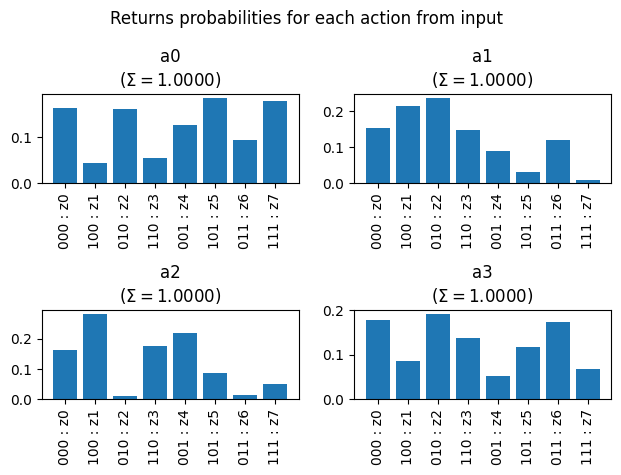

Compounded: [0.59623421 0.0622497  0.08029211 0.26122398]


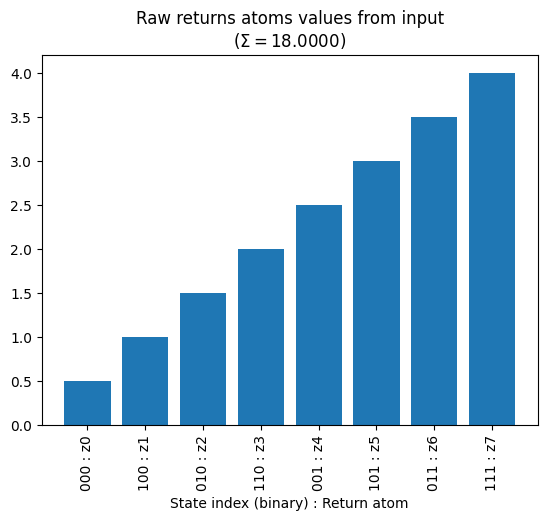

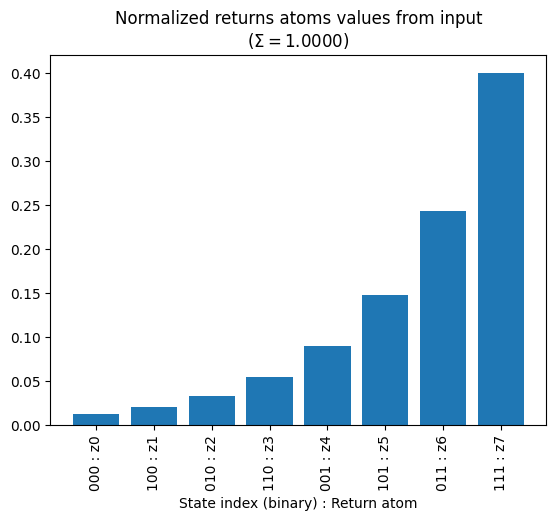

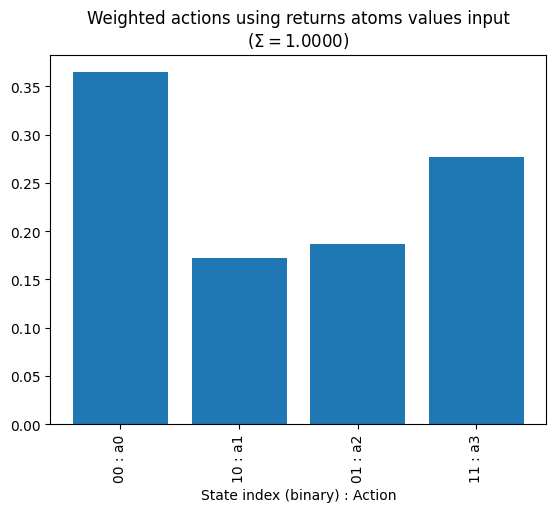

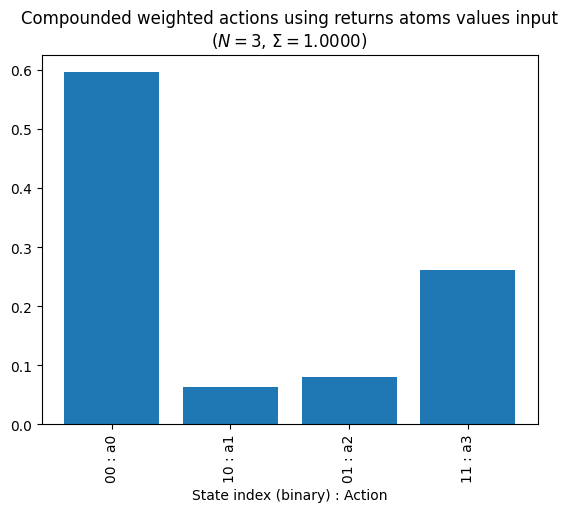

In [21]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(jnp.arange(n_actions), action_probs_vec)
plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from input\n($\\Sigma = {action_probs_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(jnp.ceil(jnp.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    y = returns_probs_matrix[a]
    axs[a].bar(jnp.arange(n_returns), y)
    axs[a].set_xticks(jnp.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}\n($\\Sigma = {y.sum():.4f}$)")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(jnp.arange(n_returns), returns_atoms_values_original)
plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Raw returns atoms values from input\n($\\Sigma = {returns_atoms_values_original.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

plt.figure()
plt.bar(jnp.arange(n_returns), returns_atoms_values_original_normalized)
plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Normalized returns atoms values from input\n($\\Sigma = {returns_atoms_values_original_normalized.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

# #########

# plt.figure()
# df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
# weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
# y = (df.T * weights).sum(axis=1).to_numpy()
# plt.bar(jnp.arange(n_returns), y)
# plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
# plt.title(f"Sum of weighted returns using action distribution from input\n($\\Sigma = {y.sum():.4f}$)")
# plt.xlabel("State index (binary) : Return atom")


# plt.figure()
# M = jnp.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
# y = jnp.abs(M)
# plt.bar(jnp.arange(n_returns), y)
# plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
# plt.title(f"Sum of weighted returns using returns atoms values from input\n($\\Sigma = {y.sum():.4f}$)")
# plt.xlabel("State index (binary) : Return atom")

# plt.figure()
# d = int(jnp.ceil(jnp.sqrt(n_actions)))
# fig, axs = plt.subplots(d, d)
# axs = axs.flatten()
# for a in range(n_actions):
#     y = returns_probs_matrix[a] * returns_atoms_values_original_normalized
#     axs[a].bar(jnp.arange(n_returns), y)
#     axs[a].set_xticks(jnp.arange(n_returns))
#     axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
#     axs[a].set_title(f"a{a}\n($\\Sigma = {y.sum():.4f}$)")
# plt.suptitle("Weighted returns using atom values from input")
# plt.tight_layout()
# plt.show()

# #########

plt.figure()
y = (returns_probs_matrix @ returns_atoms_values_original_normalized) # Perform expected value once.
y /= y.sum() # Normalize.
plt.bar(jnp.arange(n_actions), y)
plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Weighted actions using returns atoms values input\n($\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

plt.figure()
# N = n_returns
N = d_returns
y = (returns_probs_matrix @ returns_atoms_values_original_normalized)**N # Perform expected value, then compound result multiple times
y /= y.sum() # Normalize.
plt.bar(jnp.arange(n_actions), y)
plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Compounded weighted actions using returns atoms values input\n($N={N}$, $\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")
print(f"Compounded: {y}")

In [22]:
# Print the circuit to ensure it is what we expect.
print(qml.draw(circuit)(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms))

0: ─╭|Ψ⟩─╭Select──────────────────╭Select──────────────────╭Select──────────────────╭Select ···
1: ─╰|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
2: ──────├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select ···
3: ──────├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select ···
4: ──────╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select ···

0: ··· ──────────────────┤ ╭Probs
1: ··· ──────────────────┤ ╰Probs
2: ··· ─╭U(M0)──┤↗│  │0⟩─┤ ╭Probs
3: ··· ─├U(M0)──┤↗│  │0⟩─┤ ├Probs
4: ··· ─╰U(M0)──┤↗│  │0⟩─┤ ╰Probs
M0 = 
[[0.31117103 0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.39955152 0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.5130343  0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.65874908 0.         0.
  0.         0.        ]
 [0

In [23]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([3164236999, 3984487275], dtype=uint32)


In [24]:
# shots = None # Exact numerical simulation.
shots = 100
# shots = 1000
(probs_actions, probs_returns) = circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, shots=shots)
# (probs_actions, probs_returns) = circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix)

print(f"{probs_actions=}")
print(f"{probs_returns=}")

probs_actions=Array([0.61, 0.05, 0.09, 0.25], dtype=float64)
probs_returns=Array([1., 0., 0., 0., 0., 0., 0., 0.], dtype=float64)


Text(0.5, 0, 'State index (binary) : Action')

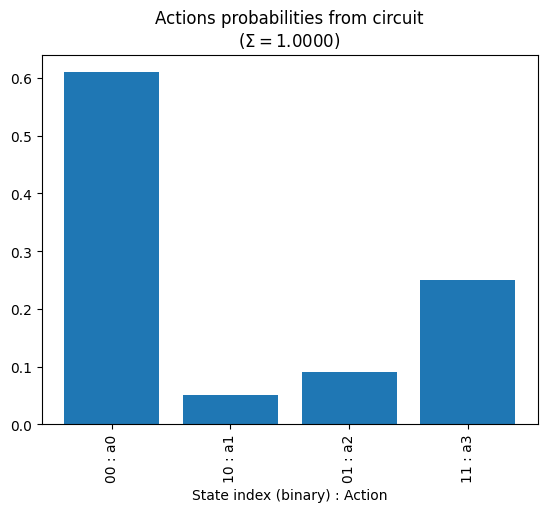

In [25]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [26]:
from collections import namedtuple
ActionRank = namedtuple("ActionRank", ["action", "rank"])

### Rank actions from high-to-low based on their weighted expected return.

action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_manual_compute = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_manual_compute)) # [(action_index, rank), ...]
print(f"action_rank_manual_compute={[a for a,r in action_rank_manual_compute]}")

### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_circuit_probs = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_circuit_probs)) # [(action_index, rank), ...]
print(f"action_rank_circuit_probs={[a for a,r in action_rank_circuit_probs]}")

action_rank_manual_compute=[0, 3, 2, 1]
action_rank_circuit_probs=[0, 3, 2, 1]


In [27]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True

In [28]:
# Check if the top 3 actions are identical.
action_rank_manual_compute[:3] == action_rank_circuit_probs[:3]

True

In [29]:
# Check if the top 3 ranks consist of the same action pool (not necessarily the same positions).
set(a for a, r in action_rank_manual_compute[:3]) == set(a for a, r in action_rank_circuit_probs[:3])

True

Text(0.5, 1.0, 'Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = True\nTop 3 rank match = True (jumbled match? True)\nTop 1 rank match = True')

<Figure size 640x480 with 0 Axes>

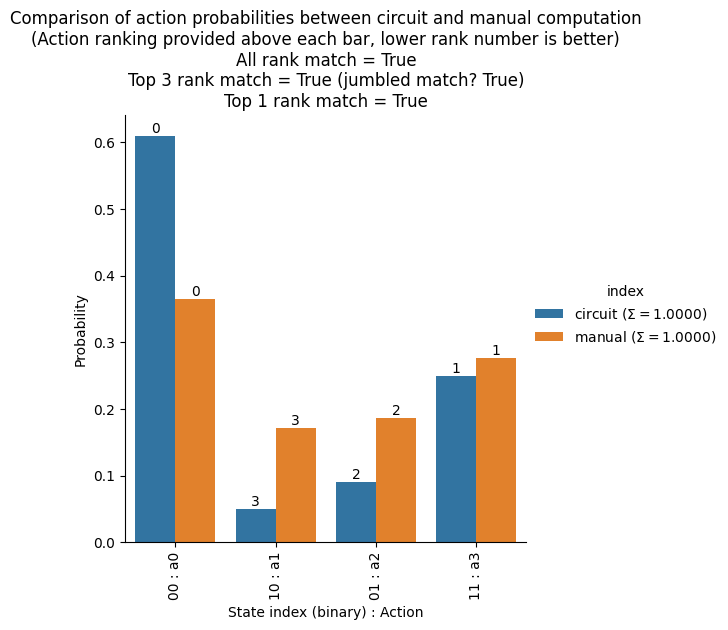

In [30]:
### To make visual comparison easier, plot action probabilities from quantum circuit and manual computation together on same chart.

# Compute manual returns probabilities.
# y = returns_probs_matrix @ returns_atoms_values_original
y = returns_probs_matrix @ returns_atoms_values_original_normalized
y /= y.sum()

# Plot circuit action probabilities and manual computation action probabilities together.
df = pd.DataFrame(np.array([probs_actions, y]), columns=[f"a{i}" for i in range(n_actions)], index=[f"circuit ($\\Sigma = {probs_actions.sum():.4f}$)", f"manual ($\\Sigma = {y.sum():.4f}$)"])
df = df.reset_index()
df = df.melt(id_vars='index')

plt.figure()
g = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax = g.facet_axis(0, 0)
for idx, (container, actionrank) in enumerate(zip(ax.containers, [action_rank_circuit_probs, action_rank_manual_compute])):
    # labels = [f"{v.get_height():.4f}" for v in container]
    actionrank = sorted(actionrank, key=lambda ar: ar.action)
    labels = [f"{actionrank[j].rank}" for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, label_type='edge')
g.set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
g.set_xlabels("State index (binary) : Action")
g.set_ylabels("Probability")
plt.title(f"Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = {action_rank_manual_compute == action_rank_circuit_probs}\nTop 3 rank match = {action_rank_manual_compute[:3] == action_rank_circuit_probs[:3]} (jumbled match? {set(a for a, r in action_rank_manual_compute[:3]) == set(a for a, r in action_rank_circuit_probs[:3])})\nTop 1 rank match = {action_rank_manual_compute[0] == action_rank_circuit_probs[0]}")